# HAEmulator: HA(シンチ)の応答

シンチのピクセルごとのエネルギー損失から、HA の ADC(1 台 24 ch = 6 PMT × 4 ch)を作ります。
実データの `ReadData` が読み、`HA_CenterGravity` と `HA_Calc` が使うのと同じ中身です。

| | |
| --- | --- |
| SMILE_tool_box | `Emu_HA` |
| ソース | `simulation_source/modules/HAEmulator/` |

## 1. 何をするか

イベントごとに:

1. `EdepPickUp` のシンチのステップを、立体の名前(`scinti_<bottom|side>_<HA>_<PMT>_<ピクセル>`)でピクセルごとに足す
2. ピクセルごとに:
   1. **分解能**: エネルギーをガウス分布でゆらす(662 keV で FWHM 11.5 %(底面の HA)、10.5 %(側面の HA)、√E に比例)
   2. **周りへのもれ**: 上下左右に 15.3 %、斜めに 3.2 % ずつ(ゆらぎ付き)
   3. **電荷分割**: 抵抗チェーンで 4 ch に分ける(`ChargeDivTemp`)。PMT のピクセルごとのゲイン(`PMT_MapDir`、無ければ 1)を掛ける
3. 3.1 ch/keV で ADC に直し、ペデスタルのゆらぎ(σ 0.8)を足す。閾値(33)以下か 4095 以上の ch は 0x2000(エラーのビット)にする

初期化のとき、この応答を逆にたどった較正値(`E_Res_662` のピクセルのピークから)を `cal_output_dir` に `Cal_HA<名前>.dat` として書きます。
シミュレーションの raw を再構成するとき、`HA_Calc` がこれを使います(`../../DataIO_example.ipynb` の 6.1 節)。

## 2. パラメータ

| パラメータ | 型 | 既定値(C++) | この設定の値 | 単位 | 説明 |
| --- | --- | --- | --- | --- | --- |
| `ChargeDivTemp` | string | (空) | {sim_data}/charge.div |  | 抵抗チェーンの電荷分割のテンプレート(charge.div) |
| `PMT_MapDir` | string | (空) | {sim_data}/PMT_Map |  | PMT のピクセルごとのゲインのマップ(HAxx_y.map)のディレクトリ |
| `E_Res_662` | string | (空) | {sim_data}/Pixel_Resolution_20190528.dat |  | ピクセルのピークと分解能のファイル(Cal_HA*.dat の計算に使う) |
| `cal_output_dir` | string | (空) | rawdata |  | Cal_HA*.dat を書くディレクトリ(空なら書かない) |
| `random_seed` | int | 4357 | 102 |  | 乱数の種(run_sim.py --seed で上書き) |

`run_sim.py --raw-dir <dir>` は `cal_output_dir` を上書きし、`--seed` は `random_seed` を `seed × 100 + 3` にします。
コードの中の固定値: 分解能(11.5 % / 10.5 %)、もれ、3.1 ch/keV、閾値 33(`HAEmulator.cc`, `HAEmulator.hh`)。

パラメータは設定ファイル `config/simulation/smile2p_flight_parma_thermal_neutron_d10_raw.json` の `response[HAEmulator].parameters` に書きます
(書き方は `config/README.md`)。1 回だけ変えて試すときは `run_sim.py ... --set response.HAEmulator.random_seed=7` で上書きします。
「既定値(C++)」は設定ファイルに書かなかったときの値です。

## 3. ほかのモジュールとのやり取り

受け取るもの: `EdepPickUp` の `ScintiStepVolume()`, `ScintiStepE()`, `EventID()`。

| 関数 | 型 | 単位 | 中身 | 使うモジュール |
| --- | --- | --- | --- | --- |
| `EventID()` | unsigned | | イベント番号 | |
| `ADC(haIndex)` | const unsigned short*(24 ch) | ADC | HA 1 台の ADC(haIndex 0〜17)。0x2000 は閾値以下などのエラー | RawWriter2p |
| `HAName(haIndex)` | int | | haIndex の HA の名前(1, 2, 3, 7, …) | RawWriter2p |

## 4. 確かめる

raw を読み直したツリーの HA の ADC の和と、真のシンチのエネルギーを比べます。

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_sim.py").exists())
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CONFIG = "smile2p_flight_parma_thermal_neutron_d10_raw"
cfg = ec.load_sim(CONFIG)
# 1_DataIO/DataIO_example.ipynb の出力(d10 の熱中性子、100 万個、seed 1)を使う
SIM = REPO / "tutorials_simulation" / "cache" / "d10_seed1_1M"
EDEP, RAW = SIM / "edep.root", SIM / "raw"
assert EDEP.exists(), "先に ../../DataIO_example.ipynb を実行してください"

def flat(column):
    # RDataFrame.AsNumpy() の vector 型の列 -> 全イベントをつないだ 1 次元の numpy 配列
    return np.concatenate([np.asarray(v) for v in column]) if len(column) else np.array([])

events: 270  ADC の ch: 432  エラー(閾値以下など)の ch の割合: 0.980


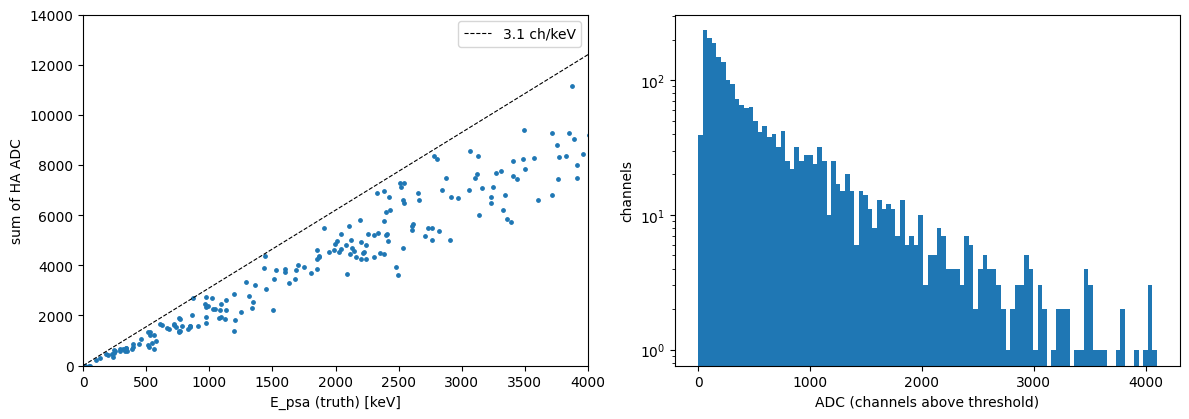

In [2]:
import subprocess
RAW_TREE = SIM / "raw_tree.root"
if not RAW_TREE.exists():   # 6_TPCEmulator と同じ
    subprocess.run([sys.executable, str(REPO / "run_script" / "run_chain.py"), "smile2p_sim_d10_recon", "-o", str(RAW_TREE), "--raw",
                    "--set", f"ReadData.data_dir={RAW}"], capture_output=True, text=True).check_returncode()
raw = (ROOT.RDataFrame("RawTreeWriter/raw", str(RAW_TREE))
         .Define("err", "ROOT::RVecI(ha_err.begin(), ha_err.end())")   # vector<char> -> 整数の配列
         .AsNumpy(["ha_adc", "err"]))
truth = ROOT.RDataFrame("sim", str(RAW / "sim_truth.root")).AsNumpy(["E_psa"])
adc = np.stack([np.asarray(v, dtype=float) for v in raw["ha_adc"]])     # events x (18 HA x 24 ch)
err = np.stack([np.asarray(v) for v in raw["err"]]).astype(bool)
adc[err] = 0
print("events:", len(adc), " ADC の ch:", adc.shape[1], " エラー(閾値以下など)の ch の割合:", f"{err.mean():.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
ax[0].scatter(truth["E_psa"], adc.sum(axis=1), s=6)
ax[0].plot([0, 4000], [0, 4000 * 3.1], "k--", lw=0.8, label="3.1 ch/keV")
ax[0].set_xlabel("E_psa (truth) [keV]"); ax[0].set_ylabel("sum of HA ADC"); ax[0].legend(); ax[0].set_xlim(0, 4000); ax[0].set_ylim(0, 14000)
ax[1].hist(adc[adc > 0], bins=100, range=(0, 4100)); ax[1].set_yscale("log"); ax[1].set_xlabel("ADC (channels above threshold)")
ax[1].set_ylabel("channels")
fig.tight_layout(); plt.show()

- 左: ADC の和はシンチのエネルギーとともに増えますが、3.1 ch/keV × `E_psa`(点線)より 3 割ほど小さく出ます。
  主な理由は PMT のピクセルごとのゲイン(`PMT_MapDir` の `HA*.map`)を掛けるためで、その平均は 0.73 です(電荷分割の比は 4 ch の和が 1)。
  さらに、閾値以下の ch と 4095 を超えた ch は 0x2000 になり、和に入りません。
  再構成の `HA_Calc` は、このゲインを入れた較正値(`Cal_HA*.dat`)でエネルギーに戻します。
- 右: 4095 の手前で ADC の分布が切れます(12 bit)。